In [1]:
import os
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import sys

# Import project modules
if "/mnt/research/ascsn/aaron-philip/barrier-extraction/src" not in sys.path:
    sys.path.append("/mnt/research/ascsn/aaron-philip/barrier-extraction/src")
from train import  init_E0, run_wong_trial, fit_wong_with_restarts, make_x_pred, draw_sigma_samples,percentile_bands,barrier_from_sigma_samples,fit_wong
from utils import load_packed_hdf5 # updated import
from wong import sigma
from train import barrier_from_sigma_samples

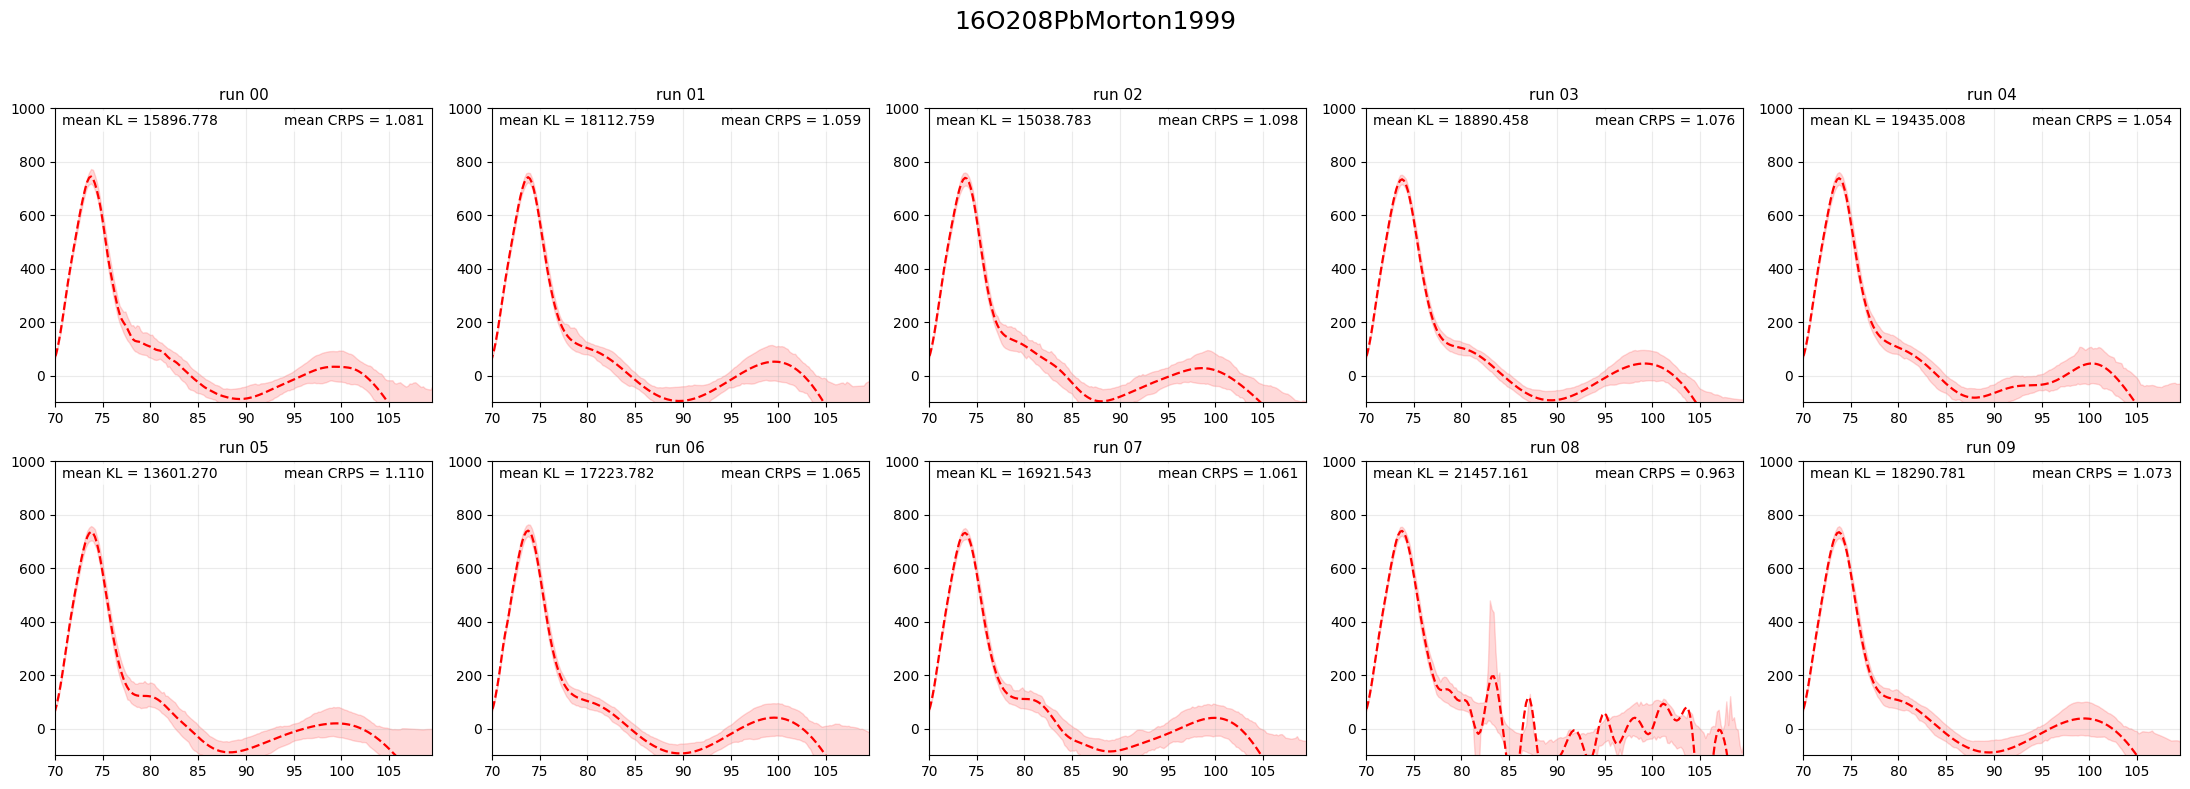

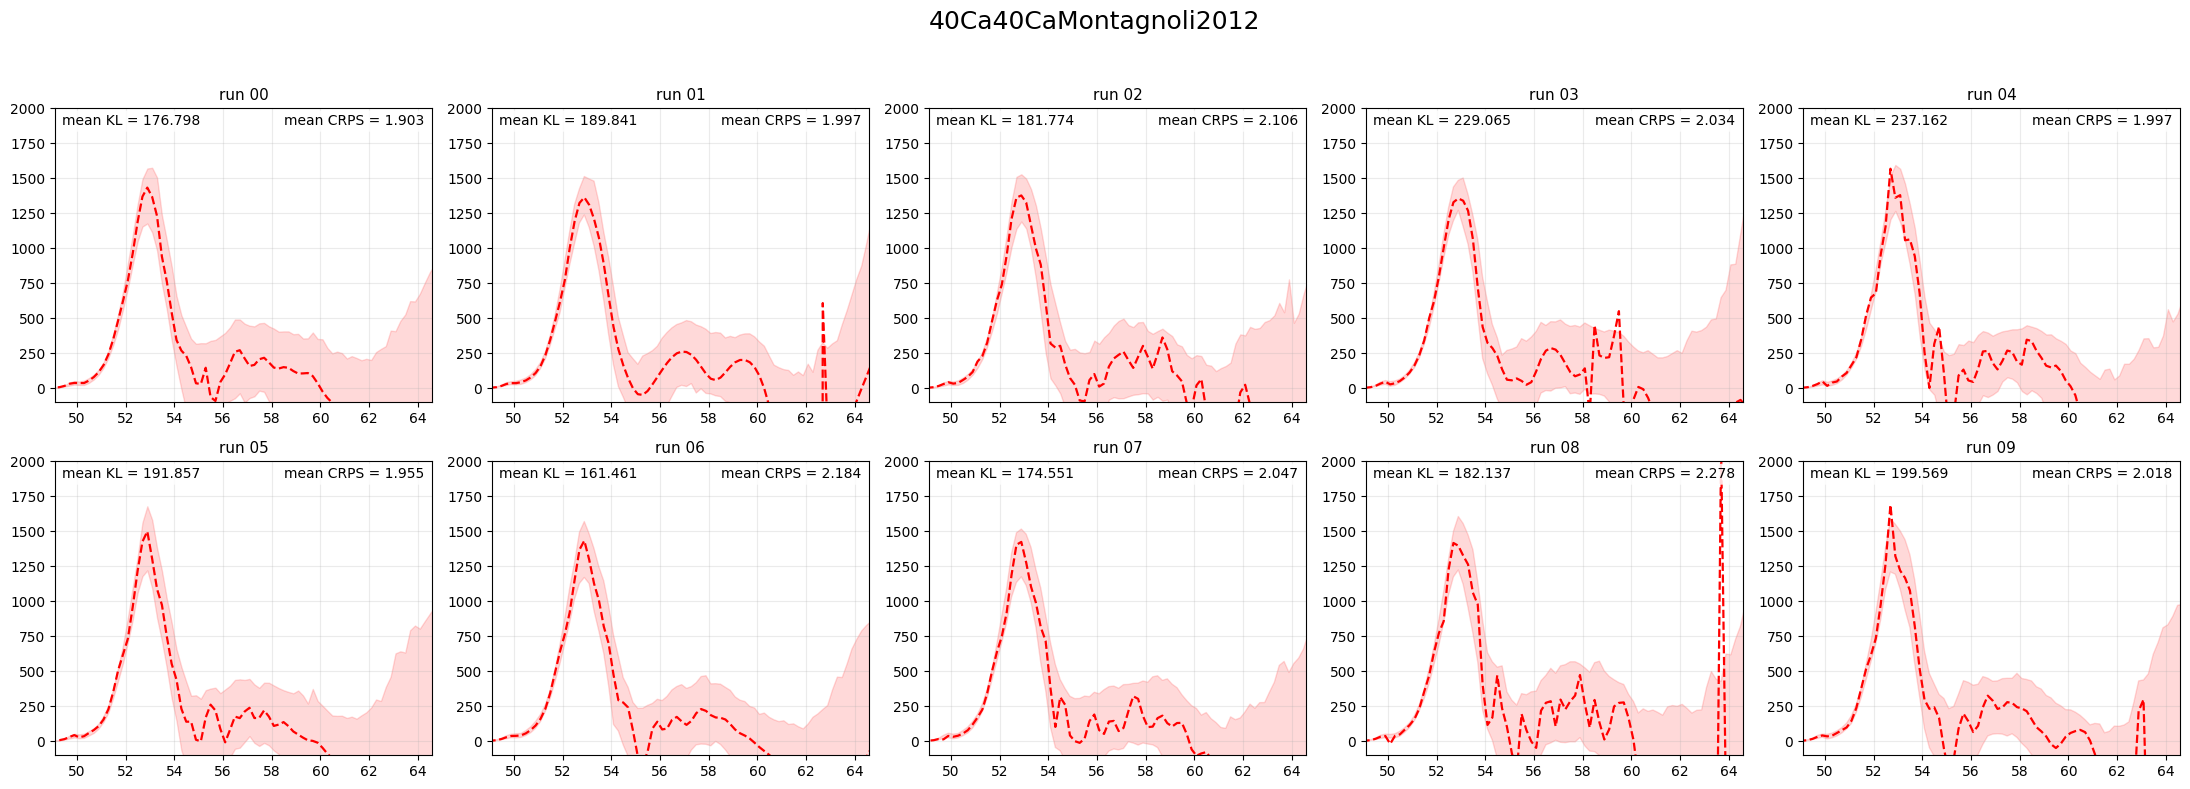

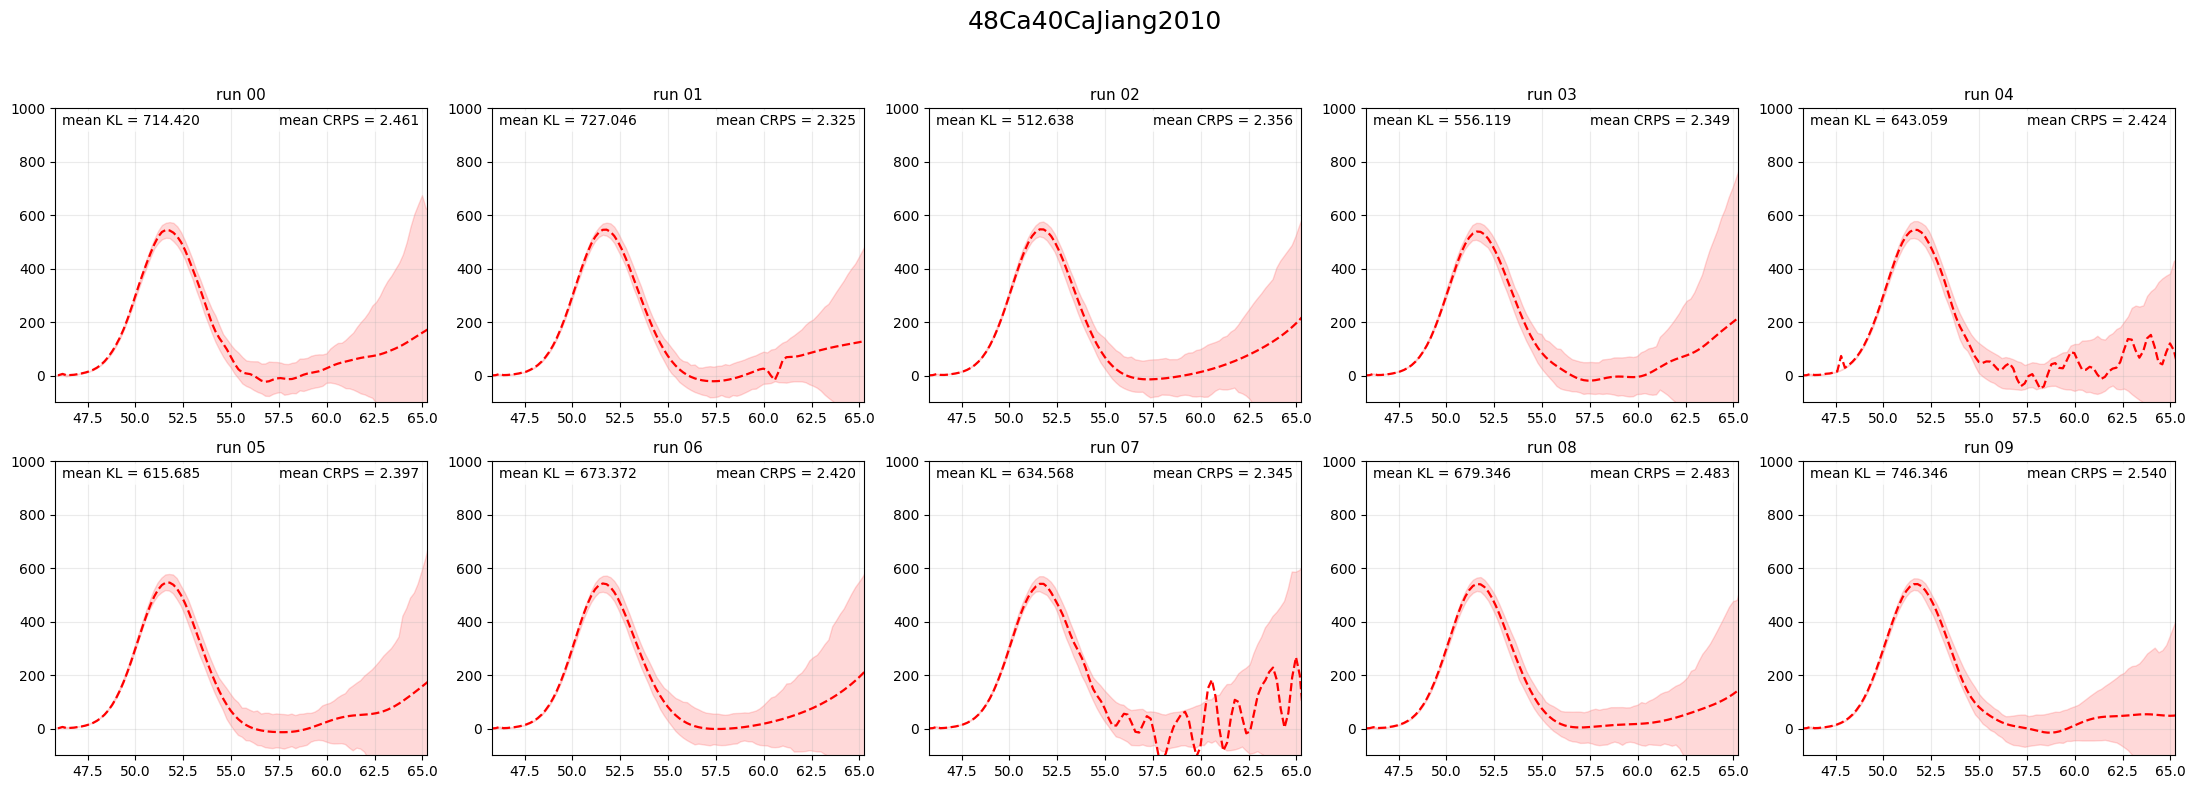

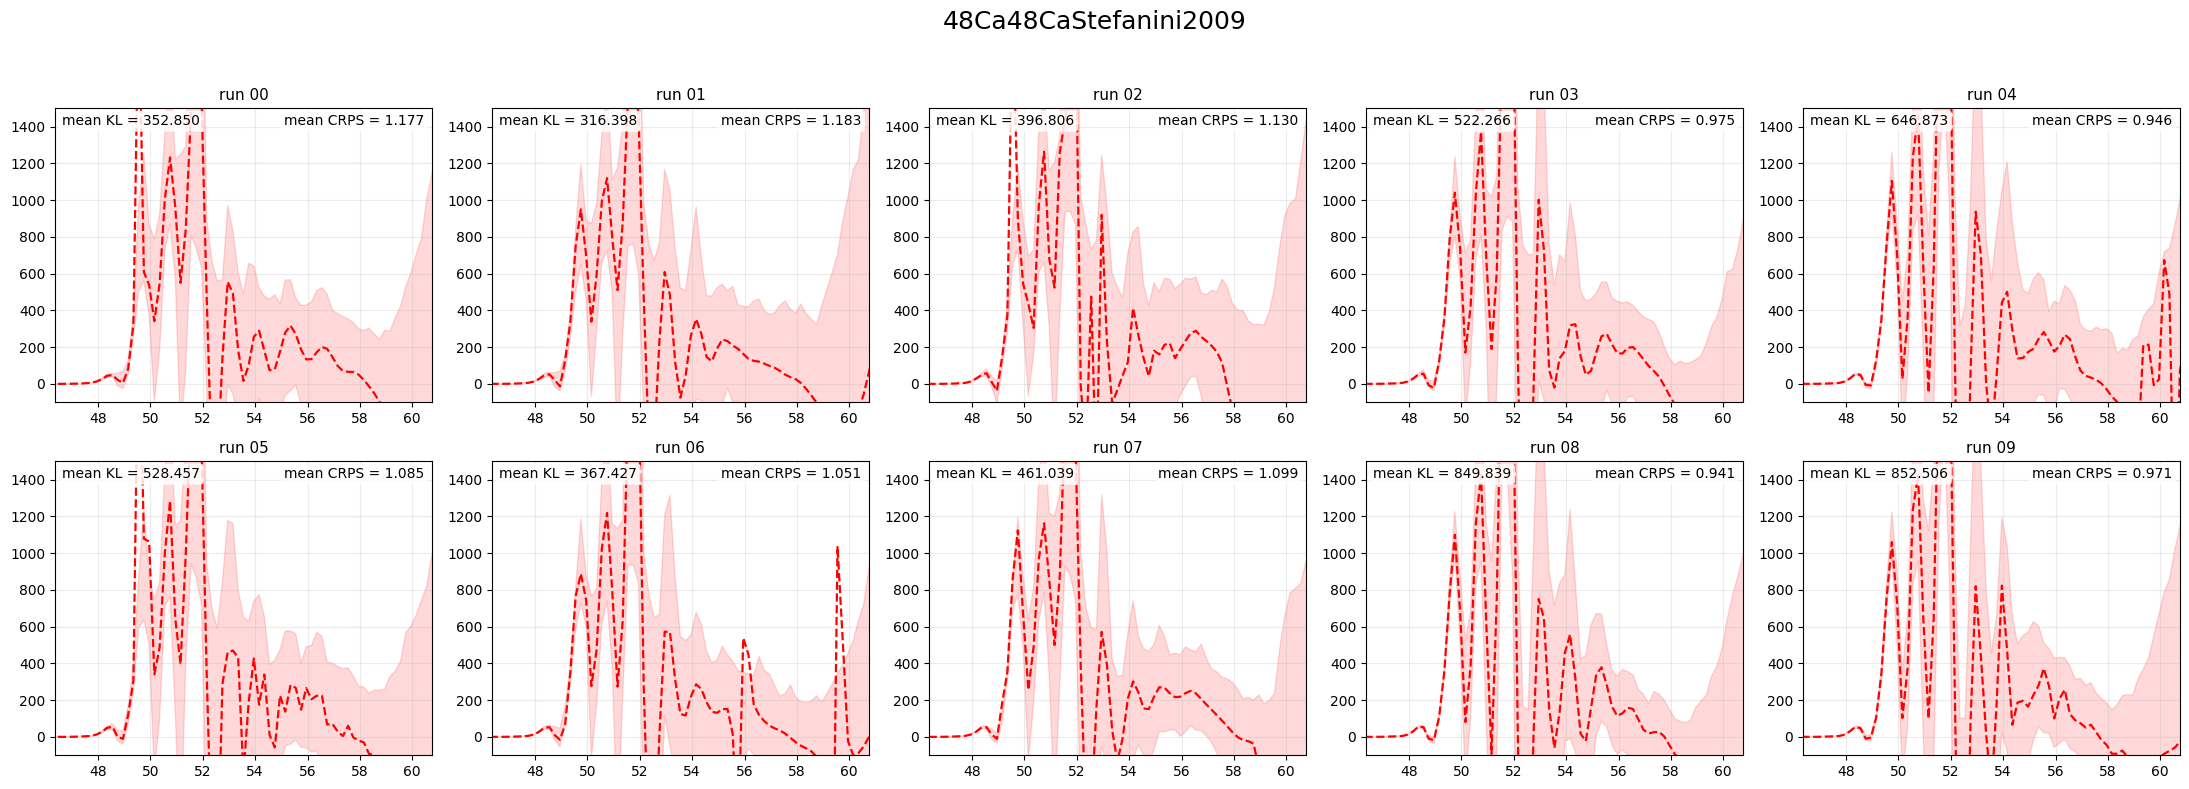


Saved metrics dataframe to:
../plots/bnn_fit_quality_metrics.csv
../plots/bnn_fit_quality_metrics.pkl

Metrics dataframe:
    dataset_idx                 dataset  run_idx   group_name  redchi2_sigma  \
0             0      16O208PbMorton1999        0  00000_run00       0.000052   
1             0      16O208PbMorton1999        1  00000_run01       0.000052   
2             0      16O208PbMorton1999        2  00000_run02       0.000058   
3             0      16O208PbMorton1999        3  00000_run03       0.000052   
4             0      16O208PbMorton1999        4  00000_run04       0.000055   
5             0      16O208PbMorton1999        5  00000_run05       0.000056   
6             0      16O208PbMorton1999        6  00000_run06       0.000051   
7             0      16O208PbMorton1999        7  00000_run07       0.000056   
8             0      16O208PbMorton1999        8  00000_run08       0.000049   
9             0      16O208PbMorton1999        9  00000_run09       0.000058 

In [7]:
def percentile_bands(samples, levels=(0.68, 0.95)):
    out = {}
    for lev in levels:
        lo = 100 * (0.5 - lev / 2.0)
        hi = 100 * (0.5 + lev / 2.0)
        out[f"lower_{int(round(100*lev))}"] = np.percentile(samples, lo, axis=0)
        out[f"upper_{int(round(100*lev))}"] = np.percentile(samples, hi, axis=0)
    return out


def crps_from_samples(y_true, y_samps):
    """
    Empirical-sample CRPS at each point.

    y_true  : (N,)
    y_samps : (S, N)
    returns : (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    term1 = np.mean(np.abs(y_samps - y_true[None, :]), axis=0)
    pairwise = np.abs(y_samps[:, None, :] - y_samps[None, :, :])
    term2 = 0.5 * np.mean(pairwise, axis=(0, 1))
    return term1 - term2


def kl_gaussian_exp_vs_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Per-point KL divergence D_KL(P_exp || Q_pred), where

      P_exp  = N(y_true, y_err^2)
      Q_pred ≈ N(mean(samples), std(samples)^2)

    y_true : (N,)
    y_err  : (N,)
    y_samps: (S, N)

    returns: (N,)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu_q = np.mean(y_samps, axis=0)
    std_q = np.std(y_samps, axis=0, ddof=1)

    std_p = np.maximum(y_err, eps)
    std_q = np.maximum(std_q, eps)

    kl = np.log(std_q / std_p) + (
        std_p**2 + (y_true - mu_q)**2
    ) / (2.0 * std_q**2) - 0.5

    return kl


def reduced_chi2(y_true, y_pred_mean, y_err, dof_correction=0, eps=1e-12):
    y_err = np.maximum(np.asarray(y_err, dtype=float), eps)
    resid = (np.asarray(y_true) - np.asarray(y_pred_mean)) / y_err
    nu = max(len(y_true) - dof_correction, 1)
    return np.sum(resid**2) / nu


def nlpd_gaussian_from_samples(y_true, y_err, y_samps, eps=1e-12):
    """
    Pointwise NLPD using Gaussian approximation to predictive samples and
    adding experimental variance in quadrature:

      y_obs ~ N(mu_pred, std_pred^2 + y_err^2)
    """
    y_true = np.asarray(y_true, dtype=float)
    y_err = np.asarray(y_err, dtype=float)
    y_samps = np.asarray(y_samps, dtype=float)

    mu = np.mean(y_samps, axis=0)
    std_pred = np.std(y_samps, axis=0, ddof=1)
    var_tot = np.maximum(std_pred**2 + y_err**2, eps)

    nlpd = 0.5 * np.log(2.0 * np.pi * var_tot) + 0.5 * (y_true - mu)**2 / var_tot
    return nlpd


def coverage95_error_from_samples(y_true, y_samps):
    """
    Returns per-point 0/1 coverage indicator converted later to a score.
    """
    lo = np.percentile(y_samps, 2.5, axis=0)
    hi = np.percentile(y_samps, 97.5, axis=0)
    covered = ((y_true >= lo) & (y_true <= hi)).astype(float)
    return covered


def make_energy_weights(E):
    """
    Quadrature-like normalized weights on experimental energies.
    """
    E = np.asarray(E, dtype=float)
    N = len(E)
    if N == 1:
        return np.array([1.0])

    w = np.zeros(N, dtype=float)
    w[0] = 0.5 * (E[1] - E[0])
    w[-1] = 0.5 * (E[-1] - E[-2])
    for i in range(1, N - 1):
        w[i] = 0.5 * (E[i + 1] - E[i - 1])

    w = np.maximum(w, 0.0)
    s = np.sum(w)
    if s <= 0:
        return np.ones(N) / N
    return w / s


def safe_log_transform(y, y_err=None, y_samps=None, eps=1e-12):
    """
    log transform for positive sigma-like quantities.
    y_err is propagated with sigma_log ~ sigma_y / y.
    """
    y = np.asarray(y, dtype=float)
    y_clip = np.maximum(y, eps)
    logy = np.log(y_clip)

    out = [logy]

    if y_err is not None:
        y_err = np.asarray(y_err, dtype=float)
        logy_err = y_err / y_clip
        out.append(logy_err)

    if y_samps is not None:
        y_samps = np.asarray(y_samps, dtype=float)
        logy_samps = np.log(np.maximum(y_samps, eps))
        out.append(logy_samps)

    return tuple(out)


def weighted_mean(vals, w):
    vals = np.asarray(vals, dtype=float)
    w = np.asarray(w, dtype=float)
    return np.sum(w * vals)


def compute_metric_bundle(E_data, Sigma_data, Sigma_err, y_samples_at_data):
    """
    Returns a dict of ~15 scalar metrics for a single run.
    Lower is better for every returned metric.
    """
    metrics = {}

    y_mean_at_data = np.mean(y_samples_at_data, axis=0)
    Ew = make_energy_weights(E_data)

    # ---------------------------
    # sigma-space, unweighted
    # ---------------------------
    metrics["redchi2_sigma"] = reduced_chi2(
        Sigma_data, y_mean_at_data, Sigma_err, dof_correction=0
    )

    nlpd_vals = nlpd_gaussian_from_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["nlpd_sigma"] = np.nanmean(nlpd_vals)

    crps_vals = crps_from_samples(Sigma_data, y_samples_at_data)
    metrics["crps_sigma"] = np.nanmean(crps_vals)

    cov95_vals = coverage95_error_from_samples(Sigma_data, y_samples_at_data)
    metrics["cov95_sigma"] = abs(np.nanmean(cov95_vals) - 0.95)

    kl_vals = kl_gaussian_exp_vs_samples(Sigma_data, Sigma_err, y_samples_at_data)
    metrics["kl_sigma"] = np.nanmean(kl_vals)

    # ---------------------------
    # sigma-space, energy weighted
    # ---------------------------
    chi2_pointwise = ((Sigma_data - y_mean_at_data) / np.maximum(Sigma_err, 1e-12))**2
    metrics["redchi2_sigma_Ew"] = weighted_mean(chi2_pointwise, Ew)

    metrics["nlpd_sigma_Ew"] = weighted_mean(nlpd_vals, Ew)
    metrics["crps_sigma_Ew"] = weighted_mean(crps_vals, Ew)
    metrics["cov95_sigma_Ew"] = abs(weighted_mean(cov95_vals, Ew) - 0.95)
    metrics["kl_sigma_Ew"] = weighted_mean(kl_vals, Ew)

    # ---------------------------
    # log-space, unweighted
    # ---------------------------
    logy, logy_err, logy_samps = safe_log_transform(
        Sigma_data, y_err=Sigma_err, y_samps=y_samples_at_data
    )
    logy_mean = np.mean(logy_samps, axis=0)

    metrics["redchi2_log"] = reduced_chi2(
        logy, logy_mean, logy_err, dof_correction=0
    )

    nlpd_log_vals = nlpd_gaussian_from_samples(logy, logy_err, logy_samps)
    metrics["nlpd_log"] = np.nanmean(nlpd_log_vals)

    crps_log_vals = crps_from_samples(logy, logy_samps)
    metrics["crps_log"] = np.nanmean(crps_log_vals)

    cov95_log_vals = coverage95_error_from_samples(logy, logy_samps)
    metrics["cov95_log"] = abs(np.nanmean(cov95_log_vals) - 0.95)

    kl_log_vals = kl_gaussian_exp_vs_samples(logy, logy_err, logy_samps)
    metrics["kl_log"] = np.nanmean(kl_log_vals)

    return metrics


# ============================================================
# configuration
# ============================================================

DE_STENCIL = 2

titles = (
    "16O208PbMorton1999",
    "40Ca40CaMontagnoli2012",
    "48Ca40CaJiang2010",
    "48Ca48CaStefanini2009",
)

ylims = [
    (-100, 1000),   # 16O208PbMorton1999
    (-100, 2000),   # 40Ca40CaMontagnoli2012
    (-100, 1000),   # 48Ca40CaJiang2010
    (-100, 1500),   # 48Ca48CaStefanini2009
]

path_base = "/mnt/home/philipaa/scratch/barrier-paper-results/experiments7"
save_dir = "../plots"

plot_idx = 8

# collect all run-level metrics here
rows = []


# ============================================================
# main loop
# ============================================================

for idx, title in enumerate(titles):
    h5_path = os.path.join(
        path_base,
        f"experiments_{title}_bnn_soc.h5_8x1000_lognormal_soc"
    )

    fig, axes = plt.subplots(2, 5, figsize=(22, 8))
    axes = axes.ravel()

    E_plot = None
    Sigma_plot = None
    y_mean_plot = None
    y_samples_plot = None
    x_plot = None

    for sub_idx in range(10):
        ax = axes[sub_idx]
        group_name = f"{int(idx):05d}_run{int(sub_idx):02d}"

        with h5py.File(h5_path, "r") as f:
            if group_name not in f:
                ax.set_visible(False)
                continue
            grp = f[group_name]

            # Load arrays
            x = grp["x_pred"][:]
            y_mean = grp["y_mean"][:]
            y_samples = grp["y_samples"][:]
            E_data = grp["E_data"][:]
            Sigma_data = grp["Sigma_data"][:]
            Sigma_err = grp["Sigma_err"][:]
            D_samples= grp["d2_samples"][:]
            D_mean = D_samples.mean(axis=0)

            if sub_idx == plot_idx:
                E_plot = E_data.copy()
                Sigma_plot = Sigma_data.copy()
                y_mean_plot = y_mean.copy()
                y_samples_plot = y_samples.copy()
                x_plot = x.copy()

        # -----------------------------------
        # Interpolate predictive samples to data energies
        # -----------------------------------
        y_samples_at_data = np.vstack([
            np.interp(E_data, x, y_samples[i]) for i in range(y_samples.shape[0])
        ])

        # metrics for this run
        metrics = compute_metric_bundle(
            E_data=E_data,
            Sigma_data=Sigma_data,
            Sigma_err=Sigma_err,
            y_samples_at_data=y_samples_at_data,
        )

        row = {
            "dataset_idx": idx,
            "dataset": title,
            "run_idx": sub_idx,
            "group_name": group_name,
        }
        row.update(metrics)
        rows.append(row)

        # -----------------------------------
        # Barrier plots
        # -----------------------------------
       # D_samples = barrier_from_sigma_samples(x, y_samples)
       # D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]

        ax.plot(x, D_mean, "--r", linewidth=1.6)

        bands = percentile_bands(D_samples, levels=(0.68,))
        D_lo = bands["lower_68"]
        D_hi = bands["upper_68"]

        ax.fill_between(x, D_lo, D_hi, color="red", alpha=0.15)

        ax.set_xlim(E_data.min(), E_data.max())
        ax.set_ylim(ylims[idx])
        ax.set_title(f"run {sub_idx:02d}", fontsize=11)
        ax.grid(True, alpha=0.25)

        # Keep your plot labels, but now tied to dataframe metrics
        ax.text(
            0.02, 0.98,
            f"mean KL = {metrics['kl_sigma']:.3f}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="white", alpha=0.85, edgecolor="none")
        )

        ax.text(
            0.98, 0.98,
            f"mean CRPS = {metrics['crps_sigma']:.3f}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="white", alpha=0.85, edgecolor="none")
        )

    fig.suptitle(title, fontsize=18)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    out_png = os.path.join(save_dir, f"barrier_runs_{title}.png")
    #fig.savefig(out_png, dpi=300)
    plt.show()

    # keep your sigma-space plot
   # if E_plot is not None:
   #     plt.figure()
   #     plt.plot(E_plot, Sigma_plot, "o")
   #     nshow = min(100, y_samples_plot.shape[0])
   #     for i in range(0, nshow, 3):
   #         plt.plot(x_plot, y_samples_plot[i], color="gray", alpha=0.4)
   #     plt.plot(x_plot, y_mean_plot, "r--")
   #     plt.ylim(Sigma_plot.min() - 100, Sigma_plot.max() * 1.2)
       # plt.show()

  #  print(f"Saved -> {out_png}")


# ============================================================
# make dataframe and save
# ============================================================

metrics_df = pd.DataFrame(rows)

csv_path = os.path.join(save_dir, "bnn_fit_quality_metrics.csv")
pkl_path = os.path.join(save_dir, "bnn_fit_quality_metrics.pkl")

metrics_df.to_csv(csv_path, index=False)
metrics_df.to_pickle(pkl_path)

print("\nSaved metrics dataframe to:")
print(csv_path)
print(pkl_path)

print("\nMetrics dataframe:")
print(metrics_df)


# ============================================================
# print best run per dataset for each metric
# ============================================================

metric_cols = [
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "cov95_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "cov95_log",
    "kl_log",
    "redchi2_sigma_Ew",
    "nlpd_sigma_Ew",
    "crps_sigma_Ew",
    "cov95_sigma_Ew",
    "kl_sigma_Ew",
]

print("\n" + "=" * 80)
print("BEST RUN INDEX PER DATASET FOR EACH METRIC")
print("=" * 80)

for metric in metric_cols:
    print(f"\nMetric: {metric}")
    for title in titles:
        df_sub = metrics_df[metrics_df["dataset"] == title].copy()
        best_row = df_sub.loc[df_sub[metric].idxmin()]
        print(
            f"  {title:28s} -> run_idx = {int(best_row['run_idx']):2d} "
            f"(score = {best_row[metric]:.6g})"
        )


# ============================================================
# optional: compact pivot summary
# ============================================================

summary_rows = []
for metric in metric_cols:
    for title in titles:
        df_sub = metrics_df[metrics_df["dataset"] == title]
        best_row = df_sub.loc[df_sub[metric].idxmin()]
        summary_rows.append({
            "metric": metric,
            "dataset": title,
            "best_run_idx": int(best_row["run_idx"]),
            "best_score": best_row[metric],
        })

best_summary_df = pd.DataFrame(summary_rows)

summary_csv = os.path.join(save_dir, "bnn_fit_quality_best_runs.csv")
best_summary_df.to_csv(summary_csv, index=False)

#print("\nSaved best-run summary to:")
#print(summary_csv)
print(best_summary_df)

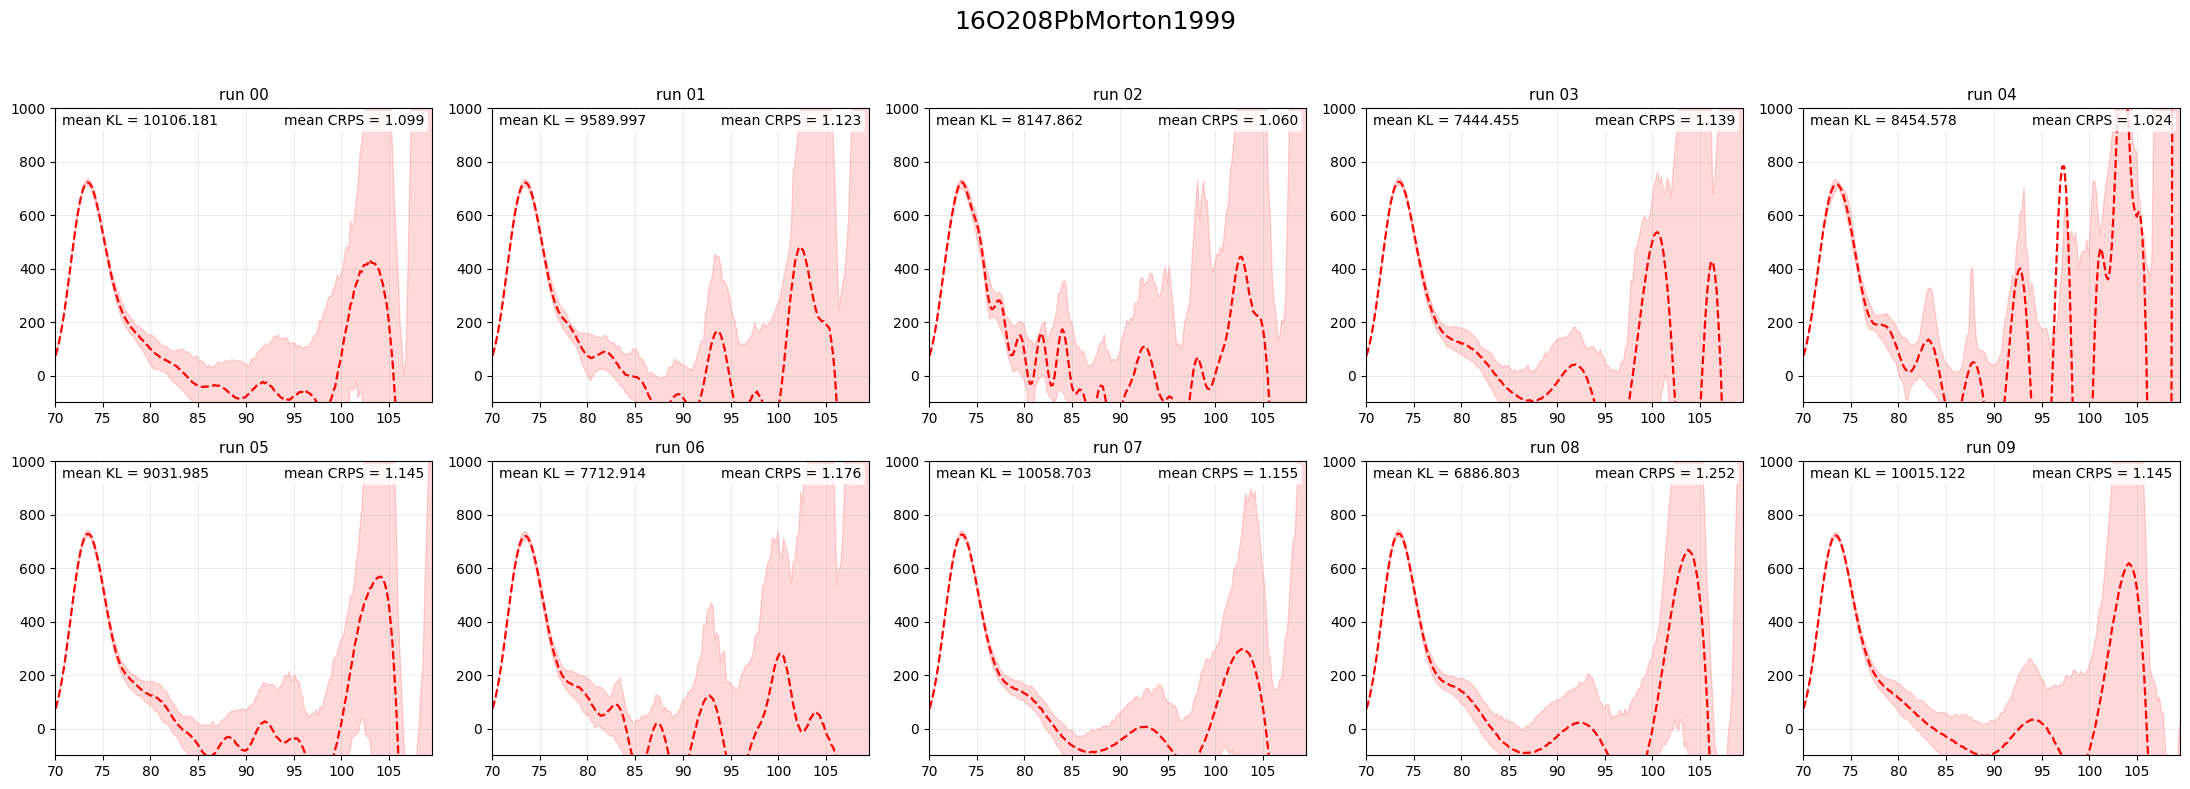

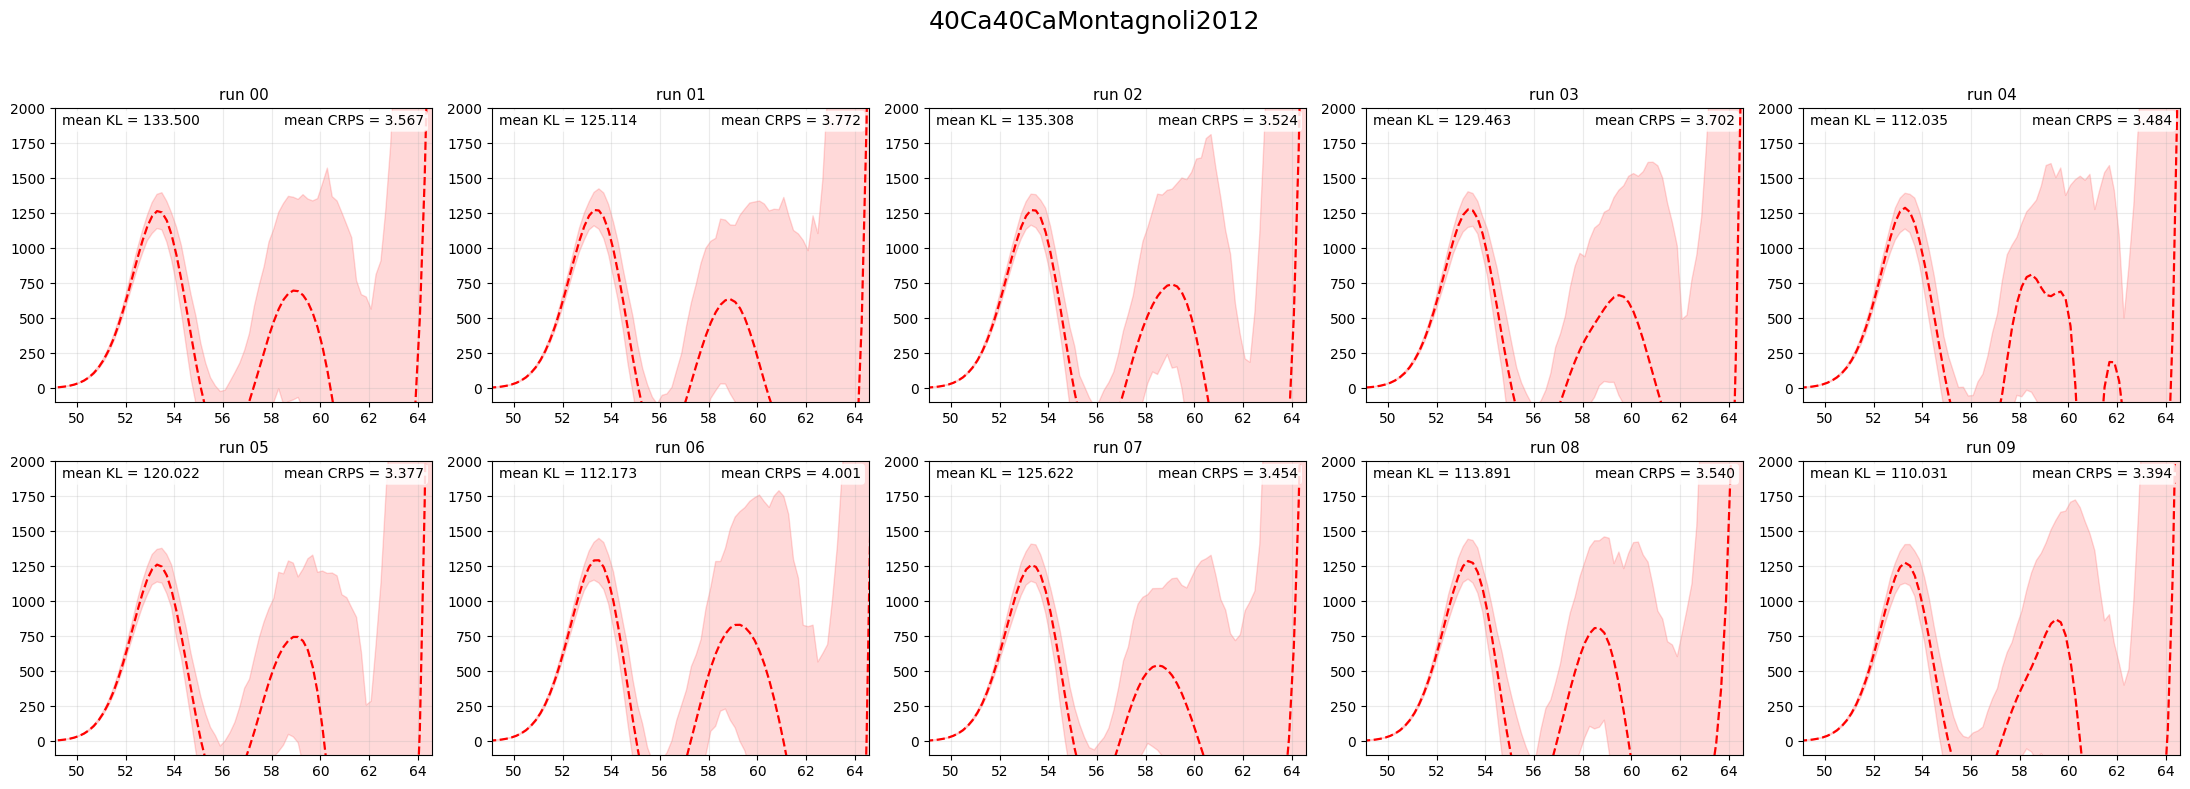

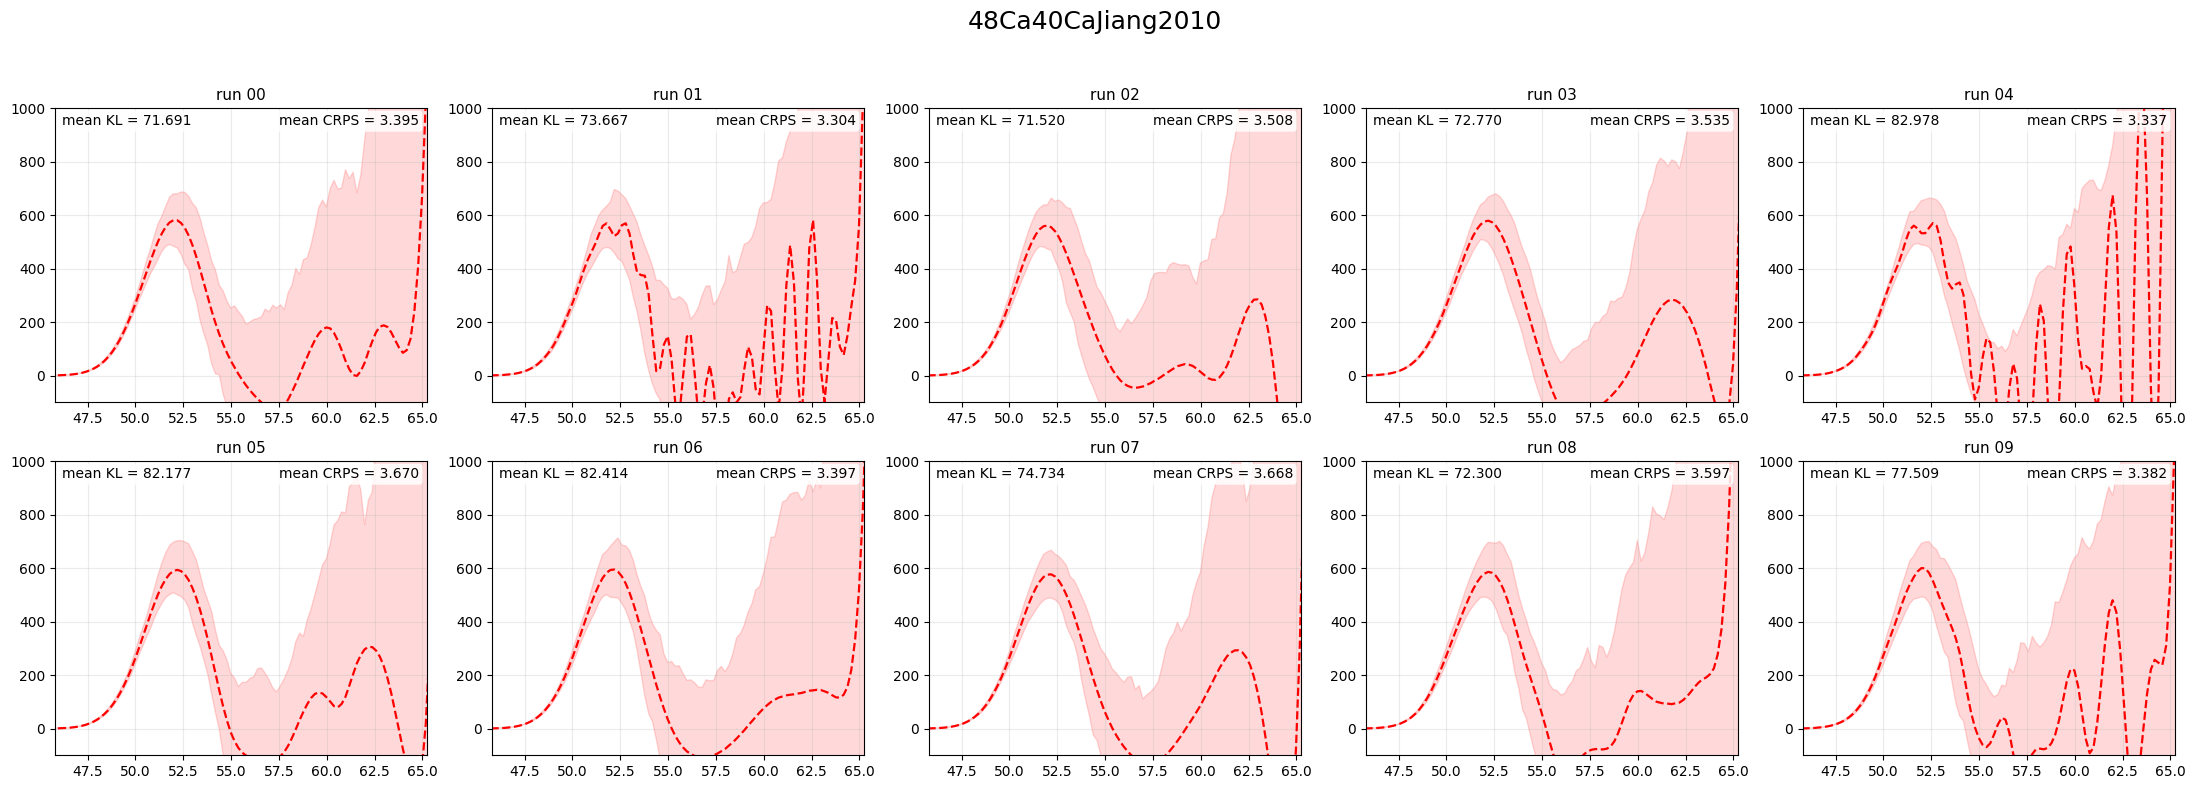

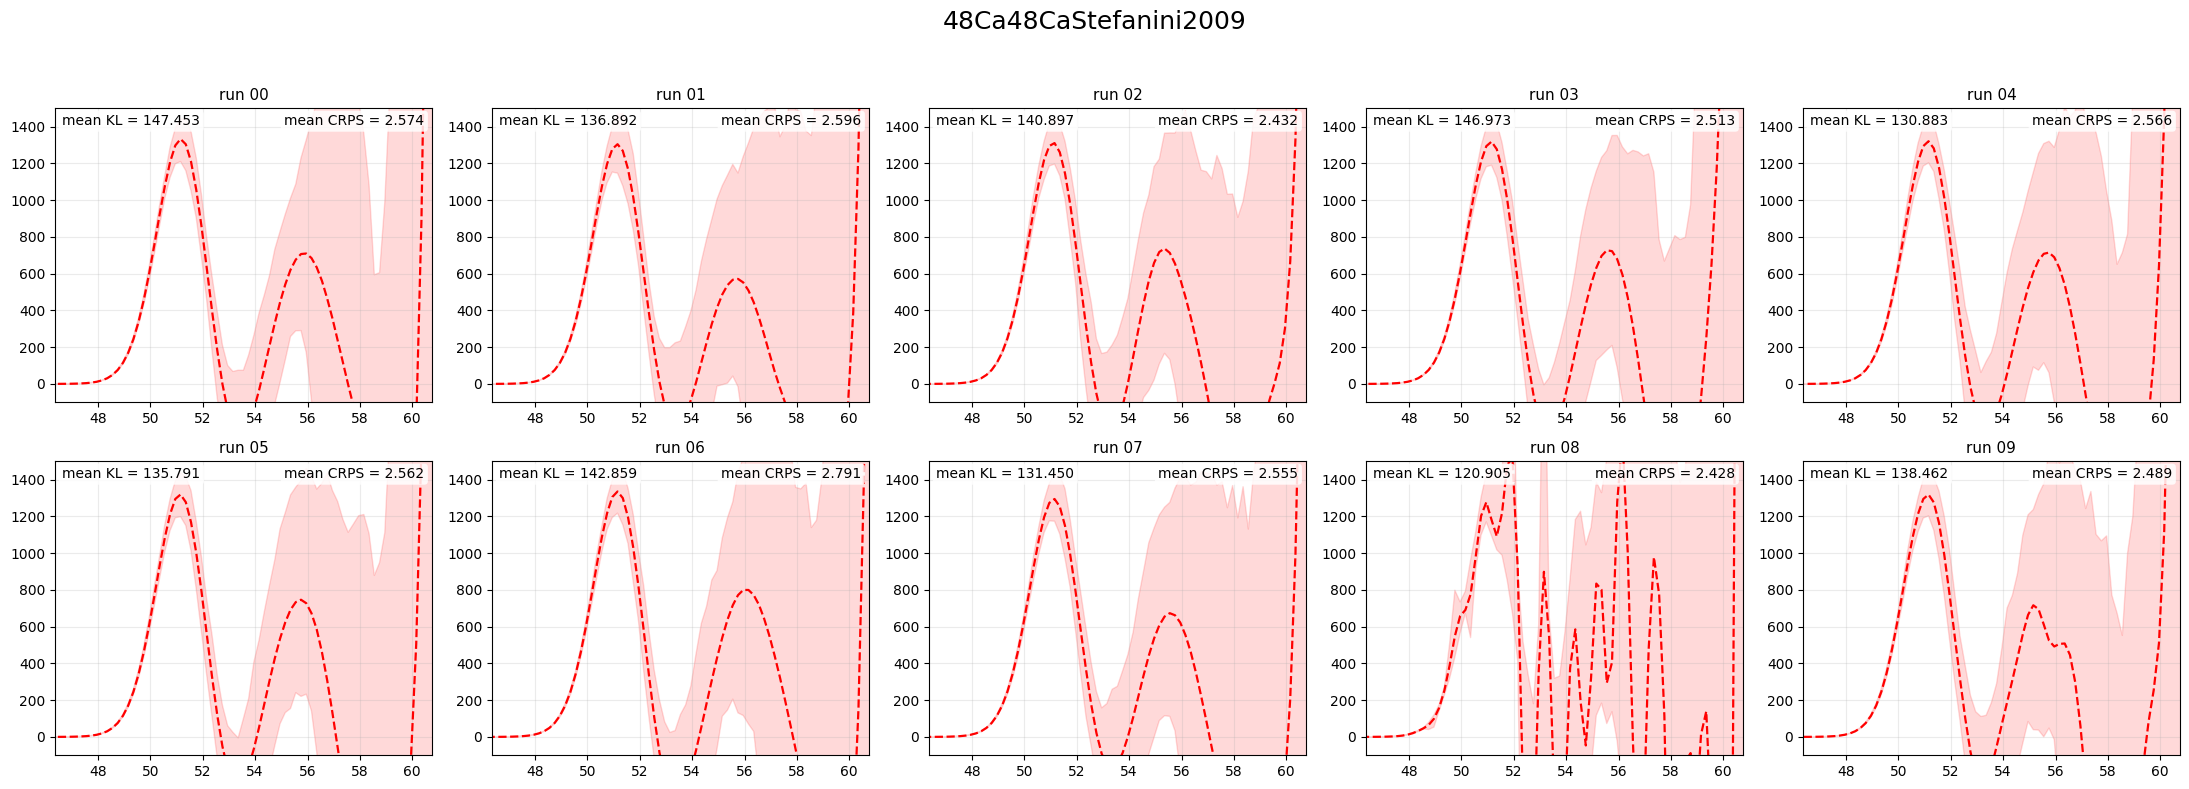


Saved metrics dataframe to:
../plots/bnn_fit_quality_metrics.csv
../plots/bnn_fit_quality_metrics.pkl

Metrics dataframe:
    dataset_idx                 dataset  run_idx   group_name  redchi2_sigma  \
0             0      16O208PbMorton1999        0  00000_run00       0.000130   
1             0      16O208PbMorton1999        1  00000_run01       0.000124   
2             0      16O208PbMorton1999        2  00000_run02       0.000110   
3             0      16O208PbMorton1999        3  00000_run03       0.000133   
4             0      16O208PbMorton1999        4  00000_run04       0.000111   
5             0      16O208PbMorton1999        5  00000_run05       0.000137   
6             0      16O208PbMorton1999        6  00000_run06       0.000123   
7             0      16O208PbMorton1999        7  00000_run07       0.000135   
8             0      16O208PbMorton1999        8  00000_run08       0.000144   
9             0      16O208PbMorton1999        9  00000_run09       0.000134 

In [3]:


# ============================================================
# configuration
# ============================================================

DE_STENCIL = 2

titles = (
    "16O208PbMorton1999",
    "40Ca40CaMontagnoli2012",
    "48Ca40CaJiang2010",
    "48Ca48CaStefanini2009",
)

ylims = [
    (-100, 1000),   # 16O208PbMorton1999
    (-100, 2000),   # 40Ca40CaMontagnoli2012
    (-100, 1000),   # 48Ca40CaJiang2010
    (-100, 1500),   # 48Ca48CaStefanini2009
]

path_base = "/mnt/home/philipaa/scratch/barrier-paper-results/experiments6"
save_dir = "../plots"

plot_idx = 8

# collect all run-level metrics here
rows = []


# ============================================================
# main loop
# ============================================================

for idx, title in enumerate(titles):
    h5_path = os.path.join(
        path_base,
        f"experiments_{title}_bnn_soc.h5_default_period_8x1000_lognormal_sup"
    )

    fig, axes = plt.subplots(2, 5, figsize=(22, 8))
    axes = axes.ravel()

    E_plot = None
    Sigma_plot = None
    y_mean_plot = None
    y_samples_plot = None
    x_plot = None

    for sub_idx in range(10):
        ax = axes[sub_idx]
        group_name = f"{int(idx):05d}_run{int(sub_idx):02d}"

        with h5py.File(h5_path, "r") as f:
            if group_name not in f:
                ax.set_visible(False)
                continue
            grp = f[group_name]

            # Load arrays
            x = grp["x_pred"][:]
            y_mean = grp["y_mean"][:]
            y_samples = grp["y_samples"][:]
            E_data = grp["E_data"][:]
            Sigma_data = grp["Sigma_data"][:]
            Sigma_err = grp["Sigma_err"][:]

            if sub_idx == plot_idx:
                E_plot = E_data.copy()
                Sigma_plot = Sigma_data.copy()
                y_mean_plot = y_mean.copy()
                y_samples_plot = y_samples.copy()
                x_plot = x.copy()

        # -----------------------------------
        # Interpolate predictive samples to data energies
        # -----------------------------------
        y_samples_at_data = np.vstack([
            np.interp(E_data, x, y_samples[i]) for i in range(y_samples.shape[0])
        ])

        # metrics for this run
        metrics = compute_metric_bundle(
            E_data=E_data,
            Sigma_data=Sigma_data,
            Sigma_err=Sigma_err,
            y_samples_at_data=y_samples_at_data,
        )

        row = {
            "dataset_idx": idx,
            "dataset": title,
            "run_idx": sub_idx,
            "group_name": group_name,
        }
        row.update(metrics)
        rows.append(row)

        # -----------------------------------
        # Barrier plots
        # -----------------------------------
        D_samples = barrier_from_sigma_samples(x, y_samples)
        D_mean = barrier_from_sigma_samples(x, y_mean.reshape(1, -1))[0]

        ax.plot(x, D_mean, "--r", linewidth=1.6)

        bands = percentile_bands(D_samples, levels=(0.68,))
        D_lo = bands["lower_68"]
        D_hi = bands["upper_68"]

        ax.fill_between(x, D_lo, D_hi, color="red", alpha=0.15)

        ax.set_xlim(E_data.min(), E_data.max())
        ax.set_ylim(ylims[idx])
        ax.set_title(f"run {sub_idx:02d}", fontsize=11)
        ax.grid(True, alpha=0.25)

        # Keep your plot labels, but now tied to dataframe metrics
        ax.text(
            0.02, 0.98,
            f"mean KL = {metrics['kl_sigma']:.3f}",
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="white", alpha=0.85, edgecolor="none")
        )

        ax.text(
            0.98, 0.98,
            f"mean CRPS = {metrics['crps_sigma']:.3f}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25",
                      facecolor="white", alpha=0.85, edgecolor="none")
        )

    fig.suptitle(title, fontsize=18)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    out_png = os.path.join(save_dir, f"barrier_runs_{title}.png")
    #fig.savefig(out_png, dpi=300)
    plt.show()

    # keep your sigma-space plot
   # if E_plot is not None:
   #     plt.figure()
   #     plt.plot(E_plot, Sigma_plot, "o")
   #     nshow = min(100, y_samples_plot.shape[0])
   #     for i in range(0, nshow, 3):
   #         plt.plot(x_plot, y_samples_plot[i], color="gray", alpha=0.4)
   #     plt.plot(x_plot, y_mean_plot, "r--")
   #     plt.ylim(Sigma_plot.min() - 100, Sigma_plot.max() * 1.2)
       # plt.show()

  #  print(f"Saved -> {out_png}")


# ============================================================
# make dataframe and save
# ============================================================

metrics_df = pd.DataFrame(rows)

csv_path = os.path.join(save_dir, "bnn_fit_quality_metrics.csv")
pkl_path = os.path.join(save_dir, "bnn_fit_quality_metrics.pkl")

metrics_df.to_csv(csv_path, index=False)
metrics_df.to_pickle(pkl_path)

print("\nSaved metrics dataframe to:")
print(csv_path)
print(pkl_path)

print("\nMetrics dataframe:")
print(metrics_df)


# ============================================================
# print best run per dataset for each metric
# ============================================================

metric_cols = [
    "redchi2_sigma",
    "nlpd_sigma",
    "crps_sigma",
    "cov95_sigma",
    "kl_sigma",
    "redchi2_log",
    "nlpd_log",
    "crps_log",
    "cov95_log",
    "kl_log",
    "redchi2_sigma_Ew",
    "nlpd_sigma_Ew",
    "crps_sigma_Ew",
    "cov95_sigma_Ew",
    "kl_sigma_Ew",
]

print("\n" + "=" * 80)
print("BEST RUN INDEX PER DATASET FOR EACH METRIC")
print("=" * 80)

for metric in metric_cols:
    print(f"\nMetric: {metric}")
    for title in titles:
        df_sub = metrics_df[metrics_df["dataset"] == title].copy()
        best_row = df_sub.loc[df_sub[metric].idxmin()]
        print(
            f"  {title:28s} -> run_idx = {int(best_row['run_idx']):2d} "
            f"(score = {best_row[metric]:.6g})"
        )


# ============================================================
# optional: compact pivot summary
# ============================================================

summary_rows = []
for metric in metric_cols:
    for title in titles:
        df_sub = metrics_df[metrics_df["dataset"] == title]
        best_row = df_sub.loc[df_sub[metric].idxmin()]
        summary_rows.append({
            "metric": metric,
            "dataset": title,
            "best_run_idx": int(best_row["run_idx"]),
            "best_score": best_row[metric],
        })

best_summary_df = pd.DataFrame(summary_rows)

summary_csv = os.path.join(save_dir, "bnn_fit_quality_best_runs.csv")
best_summary_df.to_csv(summary_csv, index=False)

#print("\nSaved best-run summary to:")
#print(summary_csv)
print(best_summary_df)